<a href="https://colab.research.google.com/github/zamoralinokevin-eng/Maestria-en-IA/blob/main/PracticaRegresionLinealMultiple_271753.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Marzo 2025
## Práctica: Práctica: Regresión Lineal Múltiple
---


## Datos del Estudiante

*   Apellidos y Nombre: Zamora Lino Kevin Josue
*   Matrícula: 271753

---



##  Objetivo de aprendizaje
Al finalizar esta práctica, el estudiante será capaz de **aplicar regresión lineal múltiple utilizando Scikit-Learn para modelar la relación entre varias variables independientes y una variable dependiente**, verificar los supuestos del modelo, interpretar los coeficientes, analizar la correlación entre predictores y evaluar el rendimiento del modelo utilizando métricas como el MSE, RMSE y R².

Datos
Trabajarás con el archivo `advertising.csv`, que contiene información sobre el gasto publicitario en diferentes medios y las ventas obtenidas:

-`TV`: inversión en publicidad televisiva.

-`Radio`: inversión en publicidad en radio.

-`Newspaper`: inversión en publicidad en periódicos.

`Sales`: ventas del producto (variable dependiente).

In [41]:
#importamos el drive para leer el archivo con los datos
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Parte 1: Carga de datos y bibliotecas
1. Importa las bibliotecas necesarias.
2. Carga el archivo `advertising.csv`.
3. Muestra las primeras filas del dataframe.
4. Describe estadísticamente las variables.

In [59]:
#importamos las bibliotecas
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import statsmodels.api as sm
import scipy.stats as stats
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

#cargamos el archivo de advertising
df = pd.read_csv('drive/MyDrive/RegresionLineal/advertising.csv')

#mostramos las primeras filas del dataframe
print(df.head(5))

#describimos estadisticamente las variables
print("\nDescripcion estadistica de las variables del dataframe:")
print(df.describe())



      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9

Descripcion estadistica de las variables del dataframe:
               TV       Radio   Newspaper       Sales
count  200.000000  200.000000  200.000000  200.000000
mean   147.042500   23.264000   30.554000   15.130500
std     85.854236   14.846809   21.778621    5.283892
min      0.700000    0.000000    0.300000    1.600000
25%     74.375000    9.975000   12.750000   11.000000
50%    149.750000   22.900000   25.750000   16.000000
75%    218.825000   36.525000   45.100000   19.050000
max    296.400000   49.600000  114.000000   27.000000


## Parte 2: Análisis exploratorio de los datos
### 2.1  Análisis de la Relación Lineal entre la variable dependiente y las independientes
1. Grafica dispersión entre cada variable independiente (`TV`, `Radio`, `Newspaper`) y `Sales`. Usa también regplot.
2. Interpreta visualmente la relación entre variables.

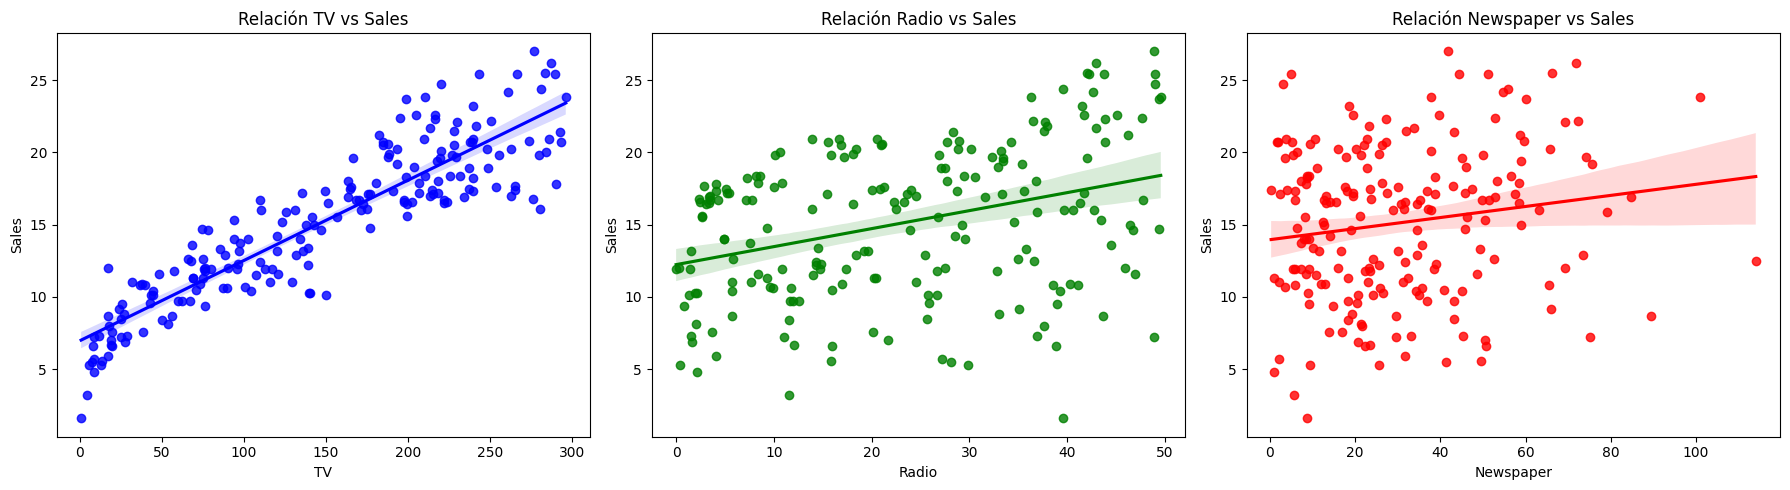

In [43]:
# Gráficos de dispersión entre cada variable independiente y sales
fix, axes = plt.subplots(1, 3, figsize=(18,5))
sns.regplot(x=df['TV'], y=df['Sales'], ax=axes[0], color='blue')
axes[0].set_title('Relación TV vs Sales')

sns.regplot(x=df['Radio'], y=df['Sales'], ax=axes[1], color='green')
axes[1].set_title('Relación Radio vs Sales')

sns.regplot(x=df['Newspaper'], y=df['Sales'], ax=axes[2], color='red')
axes[2].set_title('Relación Newspaper vs Sales')

plt.tight_layout()
plt.show()



##Intepretación visual:
TV vs Sales: se muestra una relación lineal positiva entre ambas variables. Esta relación esta bien definida y tiene poca dispersión de los datos.
Radio vs Sales: Muestra una relación lineal positiva pero con mayor dispersión de los datos que la anterior.
Newspaper vs Sales: la nube de puntos que se aprecia está dispersa con la linea de tendencia ligeramente inclinada hacia arriba. Refleja una relacion lineal entre ambas variables muy baja.

### 2.2: Correlación entre variables
1. Calcula la matriz de correlación.
2. Visualízala con un heatmap.
3. Responde: ¿Qué variables están más correlacionadas con `Sales`? ¿Hay correlación alta entre predictores?

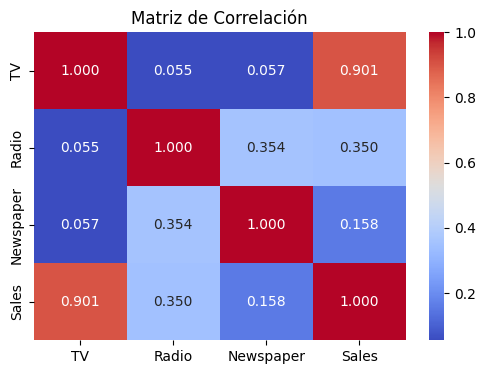

In [44]:
# Correlación y heatmap, se calcula la matriz de correlación
matriz_corr = df.corr()

#se visualiza la matriz con un heatmap
plt.figure(figsize=(6,4))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt='.3f')
plt.title('Matriz de Correlación')
plt.show()


##¿Qué variables están más correlacionadas con `Sales`? ¿Hay correlación alta entre predictores
La variable que está mas correlacionada con Sales es TV ya que tiene un valor de .0.901. A esta le sigue Radio con un valor de 0.350. La variable que tiene el coeficiente mas bajo es Newspaper con un valor de 0.158.
No existe una corelación alta etre predictores. Solo se aprecia una correlación de 0.354 entre las variables independientes Radio y Newspaper. La correlación entre las otras variables independientes son menores a 0.058

## Parte 3. Multicolinealidad
1. Calcula el VIF (Variance Inflation Factor) para cada predictor.
2. Crea un diagrama de barras  para mostrar el  VIF
3. Interpreta si hay multicolinealidad:
- ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?
- ¿Qué implicaciones tiene esto para el modelo?

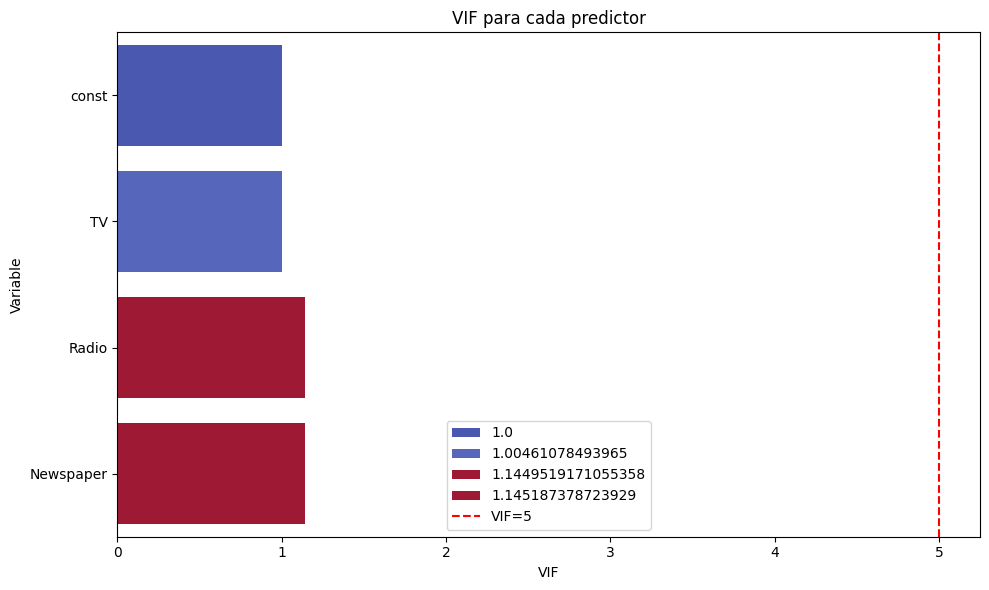

In [45]:
#Multicolinealidad, se calcula el Variance Inflation Factor
X_ = add_constant(df[['TV','Radio','Newspaper']])

vif = pd.DataFrame()
vif['Variable'] = X_.columns
vif['VIF'] = [variance_inflation_factor(X_.values, i) for i in range(X_.shape[1])]

#se crea el diagrama de barras para mostrar el VIF
plt.figure(figsize=(10,6))
sns.barplot(x='VIF', y='Variable', hue='VIF', data=vif, palette='coolwarm')
plt.axvline(x=5, color='red', linestyle='--', label='VIF=5')
plt.title('VIF para cada predictor')
plt.legend()
plt.tight_layout()
plt.show()


##Interpreta si hay multicolinealidad: ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10? ¿Qué implicaciones tiene esto para el modelo?
No hay multicolinealidad porque todos los valores son cercanos a 1, esto significa que estan muy por debajo del límite crítico de 5. Ninguna variable tiene un VIF mayor a 5.
Las implicaciones que tiene esto para el modelo es que no existe multicolinealidad entre lasvariables predictoras. Los coeficientes que se calculen van a ser estables y la varianza no estará inflada.

## Parte 4: Construcción del Modelo (Todas las variables Independientes), Evaluación

### 4.1 Entrenamiento del Modelo (Todas las Variables Independientes)

1. Entrena un modelo de regresión lineal múltiple usando TV, Radio y Newspaper como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [46]:
#ntrenamiento del Modelo (Todas las Variables Independientes)
X = df[['TV','Radio','Newspaper']]
y = df['Sales']

model_all = LinearRegression()
model_all.fit(X,y)

y_pred_all = model_all.predict(X)

print(f'Intercepto: {model_all.intercept_:.4f}')
for var, coef in zip(X.columns, model_all.coef_):
    print(f"Coeficiente {var} (Beta): {coef:.4f}")

Intercepto: 4.6251
Coeficiente TV (Beta): 0.0544
Coeficiente Radio (Beta): 0.1070
Coeficiente Newspaper (Beta): 0.0003


##¿Qué significa cada uno de los coeficientes en términos de ventas?
El intercepto con valor de 4.6251  se interpreta como si el gasto de las demas variables fuera cero, las ventas serían de 4.6251 unidades.
TV: si las demas variables fueran cero, las ventas incrementarían 0.0544 unidades.
Radio: Si las demas variables fueran cero, las ventas incrementarían 0.1070 unidades.
Newspaper: si las demas variables fueran cero, las ventas incrementarían 0.003 unidades.

### 4.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

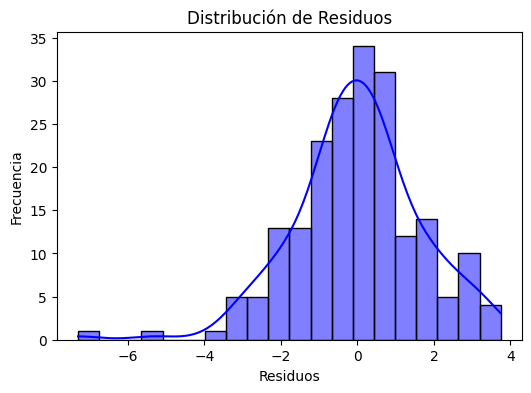

In [47]:
#Normalidad de los residuos
residuos_all = y - y_pred_all

plt.figure(figsize=(6, 4))
sns.histplot(residuos_all, kde=True, color='blue', bins=20)
plt.title('Distribución de Residuos')
plt.xlabel('Residuos')
plt.ylabel('Frecuencia')
plt.show()

##¿Los residuos parecen distribuirse normalmente?
El histograma muestra la distribucion de los residuos de una forma similar a la distribución normal pero con asimetria hacia la izquierda lo que puede indicar la presencia de outliers por debajo del limite inferior.

### 4.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

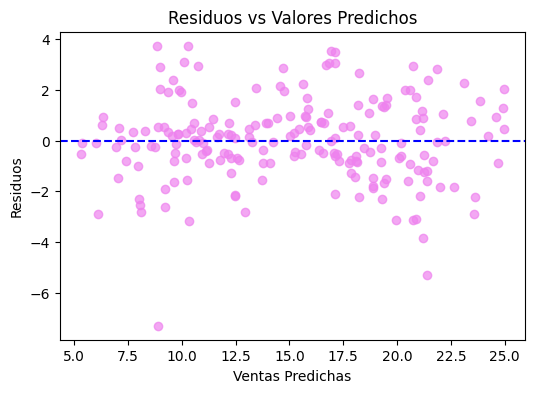

In [48]:
# Homocedasticidad
plt.figure(figsize=(6, 4))
plt.scatter(y_pred_all, residuos_all, color='violet', alpha=0.7)
plt.axhline(y=0, color='blue', linestyle='--')
plt.title('Residuos vs Valores Predichos')
plt.xlabel('Ventas Predichas')
plt.ylabel('Residuos')
plt.show()

##¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?
En el diagrama de dispersión se aprecian que los residuos de dispersan de forma aleatoria alrededor de la linea horizontal cero habiendo valores positivos y negativos, siendo algo favorable. No existe el patrón de embudo, se aprecian outliers (-7). Se puede decir que la homocedasticidad se cumple en la gráfica

### 4.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

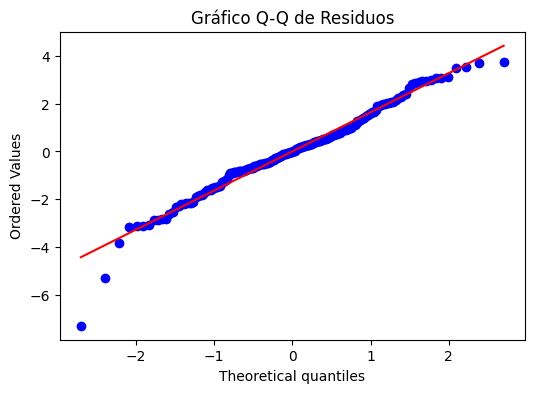

In [50]:
#Q-Q Plot
plt.figure(figsize=(6, 4))
stats.probplot(residuos_all, dist="norm", plot=plt)
plt.title('Gráfico Q-Q de Residuos del modelo')
plt.show()

##Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.
EN la gráfica que observa que los puntos de los residuos en el centro siguen muy de cerca la linea diagonal de referencia. Sólo en los extremos de la gráfica se aprecian las desviaciones de las colas superior e inferior. Se puede concluir que los residuos estan distribuidos de forma normal.

### 4.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?


In [53]:
#Evaluación del Modelo
mse_all = mean_squared_error(y, y_pred_all)
rmse_all = np.sqrt(mse_all)
r2_all = r2_score(y, y_pred_all)

print(f"MSE: {mse_all:.4f}")
print(f"RMSE: {rmse_all:.4f}")
print(f"R²: {r2_all:.4f}")

MSE: 2.7060
RMSE: 1.6450
R²: 0.9026


##¿Qué nos dicen estas métricas sobre el ajuste del modelo?
Las métricas reflejan que existe un buen ajuste del modelo ya que el valor de R2 es 0.9026 lo que interpretado es que el modelo explica el 90.2% de la variabilidad de las ventas con las 3 variables independientes. El error típico RMSE es de 1.645 unidades.

### 4.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.
3.¿Qué observas?¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

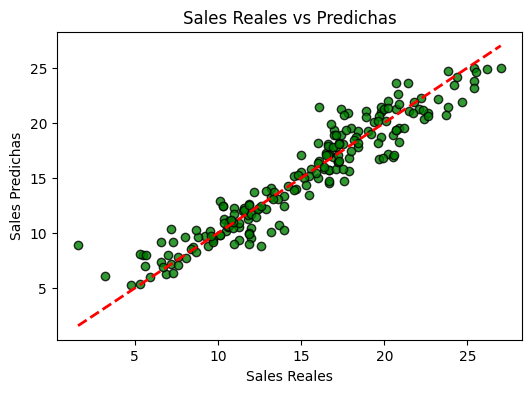

In [55]:
#Visualización de las Predicciones
plt.figure(figsize=(6, 4))
plt.scatter(y, y_pred_all, color='green', edgecolor='k', alpha=0.8)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
plt.title('Sales Reales vs Predichas')
plt.xlabel('Sales Reales')
plt.ylabel('Sales Predichas')
plt.show()

##¿Qué observas?¿Qué observas? ¿Qué información puedes obtener de esta gráfica?
Lo que se observa en el diagrama de dispersión es que los puntos estan cerca de la diagonal y bien distribuidos, no existen puntos dispersos lejanos a la diagonal. Esto significa que el modelo es preciso para predecir la variable dependiente y que no hay problemas con subestimación o sobreestimación

### 4.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?


In [60]:
#P-values
X_all_const = sm.add_constant(X_)
sm_model_all = sm.OLS(y, X_all_const).fit()
print(sm_model_all.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6251      0.308     15.041      0.000       4.019       5.232
TV             0.0544      0.001     39.592      0.000       0.052       0.057
Radio          0.1070      0.008     12.604      0.000       0.090       0.124
Newspaper      0.0003      0.006      0.058      0.954      -0.011       0.012


##¿Qué variables tienen p-value menores a 0.05? ¿Cuál es la conclusión sobre esas variables?
Las variables que tienen p-value < a 0.05 son TV y Radio. la conclusión es que estas 2 variables tienen influencia significativa en la variable ventas, mientras que la variable Newspaper, por su p-value de 0.954 no es estadisticamente significativa y no aporta valor predictivo.

##Parte 5:  Construcción del Modelo (sin Multicolinealidad), Evaluación

En el caso de que hayas detectado variables con multicolinealidad. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

Respuesta: En la parte 3 se demostró analíticamente que ninguna variable presenta multicolinealidad  ya que los VIF calculados eran muy próximos a 1. Por este supuesto, no se elimina ninguna variable. El modelo resultante es el mismo que el de la parte 4.

## Parte 6: Construcción del Modelo (sin variables que no muestran una relación lineal), Evaluación

En el caso de que hayas detectado variables sin una relación lineal con la variable dependiente. Elimina aquellas que presenten esta característica y realiza lo siguiente.

En el caso de que hayas detectado variables sin una relación lineal. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

Respuesta: La variable Newspaper, con el p-value de 0.954 lo cual no es estadisticamente significativo para predecir en el modelo, se elimina y reconstruye el modelo con las variables TV y Radio.

In [62]:
#6.1 Entrenamiento del Modelo
X_reducido = df[['TV', 'Radio']]
y = df['Sales']

model_red = LinearRegression()
model_red.fit(X_reducido, y)
y_pred_red = model_red.predict(X_reducido)

print(f"Intercepto: {model_red.intercept_:.4f}")
print(f"Coeficiente TV: {model_red.coef_[0]:.4f}")
print(f"Coeficiente Radio: {model_red.coef_[1]:.4f}")

Intercepto: 4.6309
Coeficiente TV: 0.0544
Coeficiente Radio: 0.1072


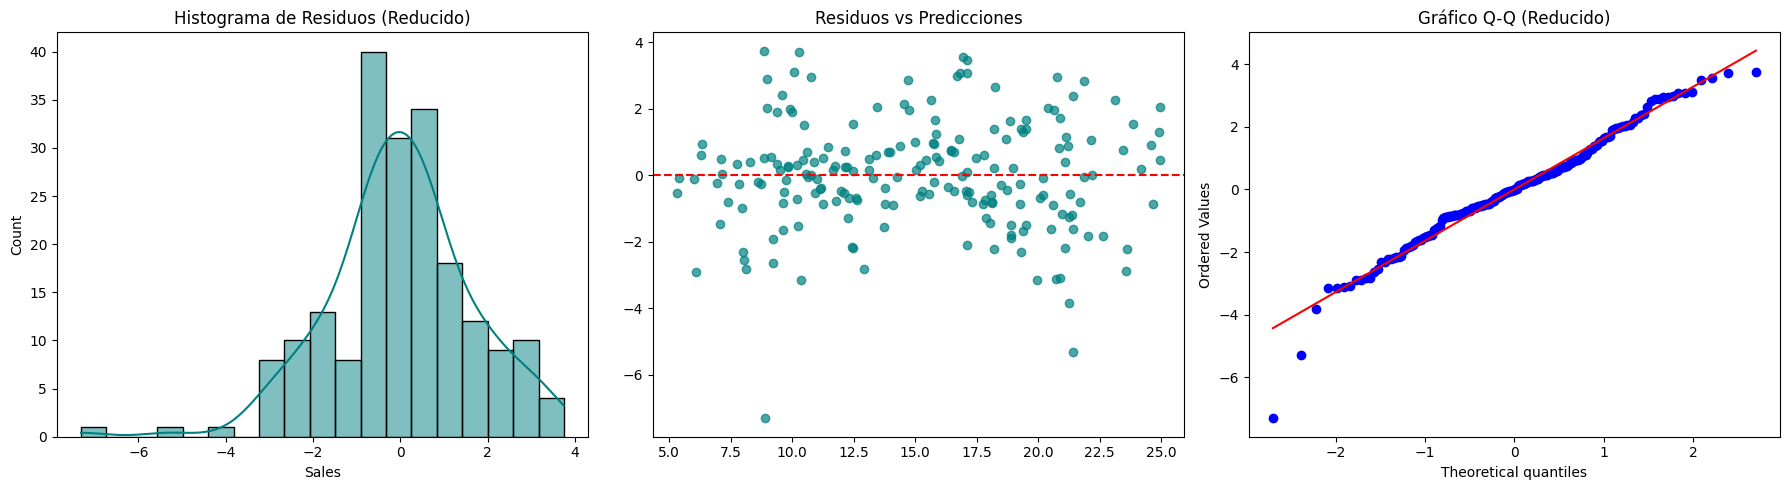

In [64]:
#calculo de normalidad, homocedasticidad y Q-Q Plot
residuos_red = y - y_pred_red
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histograma
sns.histplot(residuos_red, kde=True, color='teal', ax=axes[0])
axes[0].set_title('Histograma de Residuos (Reducido)')

# Homocedasticidad
axes[1].scatter(y_pred_red, residuos_red, color='teal', alpha=0.7)
axes[1].axhline(y=0, color='r', linestyle='--')
axes[1].set_title('Residuos vs Predicciones')

# Q-Q plot
stats.probplot(residuos_red, dist="norm", plot=axes[2])
axes[2].set_title('Gráfico Q-Q (Reducido)')

plt.tight_layout()
plt.show()

In [68]:
#evaluación del modelo modificado
mse_red = mean_squared_error(y, y_pred_red)
rmse_red = np.sqrt(mse_red)
r2_red = r2_score(y, y_pred_red)

print(f"MSE Reducido: {mse_red:.4f}  \nRMSE Reducido: {rmse_red:.4f} \nR² Reducido: {r2_red:.4f}")

#p-values del modelo modificado
X_red_const = sm.add_constant(X_reducido)
print()
print(sm.OLS(y, X_red_const).fit().summary().tables[1])

MSE Reducido: 2.7061  
RMSE Reducido: 1.6450 
R² Reducido: 0.9026

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6309      0.290     15.952      0.000       4.058       5.203
TV             0.0544      0.001     39.726      0.000       0.052       0.057
Radio          0.1072      0.008     13.522      0.000       0.092       0.123


##7. Conclusiones.

¿Cuál de los tres modelos construidos fue el mejor?
¿Cuál fue el atributo que mas influencia tiene en las ventas?

Respuesta: El modelo que se modificó en la parte 6, debido a que se eliminó una variable que no aportaba en la predicción fue mejor que el modelo inicial. Las métricas p-value de TV y Radio fue la misma en ambos modelos, pero lo que le lleba ventaja al útimo fue que es mas simple por el uso de una variable menos, eliminando el ruido que generaba Newspaper.
El atributo que mas influencia tiene en las ventas es Radio con un coeficiente beta de 0.1070. Se puede interpretar como por cada unidad de inversion en radio (beta 0.1070) se genera el doble de venta que por la unidad de inversión en TV (beta 0.054)